## 2. Loading Trained Models

The three machine learning models were trained and saved in the previous notebook.

In this step, we will load the saved models using Joblib.

This allows us to evaluate and compare the models without training them again.

In [4]:
import joblib

logistic_model = joblib.load("../models/logistic_regression.pkl")
decision_tree_model = joblib.load("../models/decision_tree.pkl")
random_forest_model = joblib.load("../models/random_forest.pkl")

print("All trained models loaded successfully!")

All trained models loaded successfully!


## 3. Loading Test Data

In this step, we will load the preprocessed test features and their corresponding actual target values.

- `X_test` contains the customer features used for prediction.
- `y_test` contains the actual churn labels (`Yes` or `No`).

We will use this data to evaluate the performance of our trained models.

In [5]:
import pandas as pd
from scipy.sparse import load_npz

# Load preprocessed test features
X_test = load_npz("../data/processed/X_test_processed.npz")

# Load actual test labels
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Test features shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

Test features shape: (1409, 46)
Test labels shape: (1409,)


## 4. Generating Predictions

In this step, we will use the three trained machine learning models to predict customer churn on the test dataset.

The predicted values will later be compared with the actual churn labels to evaluate and compare model performance.

In [6]:
# Generate predictions using each model

y_pred_logistic = logistic_model.predict(X_test)

y_pred_tree = decision_tree_model.predict(X_test)

y_pred_rf = random_forest_model.predict(X_test)

In [7]:
print("Actual values:")
print(y_test.head(10).values)

print("\nLogistic Regression predictions:")
print(y_pred_logistic[:10])

print("\nDecision Tree predictions:")
print(y_pred_tree[:10])

print("\nRandom Forest predictions:")
print(y_pred_rf[:10])

Actual values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str

Logistic Regression predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Decision Tree predictions:
['No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'Yes']

Random Forest predictions:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


## 5. Model Performance Evaluation

In this section, we will evaluate the performance of all three trained models using important classification metrics.

The metrics include:

- Accuracy
- Precision
- Recall
- F1-score

These metrics help us understand how effectively each model identifies customers who are likely to churn.

### 5.1 Accuracy Score

Accuracy measures the proportion of correctly predicted customer churn outcomes out of all predictions.

We will calculate the accuracy of Logistic Regression, Decision Tree and Random Forest to compare their overall prediction performance.

In [8]:
from sklearn.metrics import accuracy_score

# Calculate accuracy for each model
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
accuracy_tree = accuracy_score(y_test, y_pred_tree)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Logistic Regression Accuracy:", accuracy_logistic)
print("Decision Tree Accuracy:", accuracy_tree)
print("Random Forest Accuracy:", accuracy_rf)

Logistic Regression Accuracy: 0.8055358410220014
Decision Tree Accuracy: 0.7224982256919801
Random Forest Accuracy: 0.7885024840312278


### 5.2 Precision, Recall and F1-score

Accuracy alone may not provide a complete picture of model performance, especially when the target classes are imbalanced.

Therefore, we will evaluate each model using:

- **Precision:** Measures how many customers predicted as churners actually churned.
- **Recall:** Measures how many actual churners were correctly identified by the model.
- **F1-score:** Represents the balance between precision and recall.

These metrics help us understand how effectively the models identify customers at risk of leaving the telecom service.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression
precision_logistic = precision_score(y_test, y_pred_logistic, pos_label="Yes")
recall_logistic = recall_score(y_test, y_pred_logistic, pos_label="Yes")
f1_logistic = f1_score(y_test, y_pred_logistic, pos_label="Yes")

# Decision Tree
precision_tree = precision_score(y_test, y_pred_tree, pos_label="Yes")
recall_tree = recall_score(y_test, y_pred_tree, pos_label="Yes")
f1_tree = f1_score(y_test, y_pred_tree, pos_label="Yes")

# Random Forest
precision_rf = precision_score(y_test, y_pred_rf, pos_label="Yes")
recall_rf = recall_score(y_test, y_pred_rf, pos_label="Yes")
f1_rf = f1_score(y_test, y_pred_rf, pos_label="Yes")

print("Logistic Regression")
print("Precision:", precision_logistic)
print("Recall:", recall_logistic)
print("F1-score:", f1_logistic)

print("\nDecision Tree")
print("Precision:", precision_tree)
print("Recall:", recall_tree)
print("F1-score:", f1_tree)

print("\nRandom Forest")
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-score:", f1_rf)

Logistic Regression
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-score: 0.6040462427745664

Decision Tree
Precision: 0.4776902887139108
Recall: 0.48663101604278075
F1-score: 0.4821192052980132

Random Forest
Precision: 0.6310344827586207
Recall: 0.4893048128342246
F1-score: 0.5512048192771084


### 5.3 Comparison of Precision, Recall and F1-score

In this step, we will visualize the precision, recall and F1-score of all three machine learning models using a grouped bar chart.

This visualization makes it easier to compare the strengths and weaknesses of each model.

C:\Users\jeevan\AppData\Local\Temp\ipykernel_23748\1926314060.py:13: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  metrics_df.set_index("Model", inplace=True)


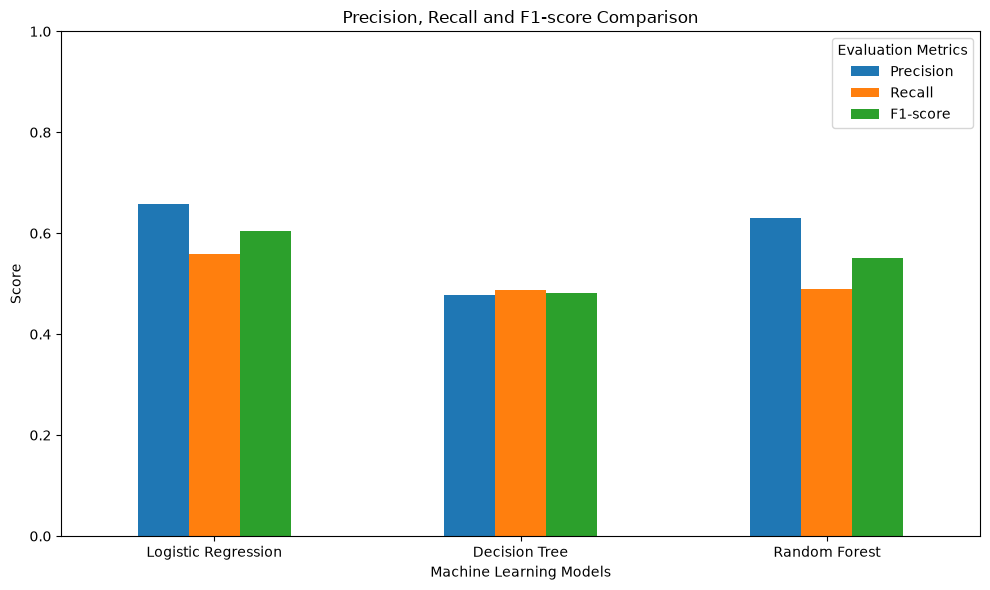

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a comparison DataFrame
metrics_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Precision": [precision_logistic, precision_tree, precision_rf],
    "Recall": [recall_logistic, recall_tree, recall_rf],
    "F1-score": [f1_logistic, f1_tree, f1_rf]
})

# Set Model as the index
metrics_df.set_index("Model", inplace=True)

# Plot the comparison
metrics_df.plot(kind="bar", figsize=(10, 6))

plt.title("Precision, Recall and F1-score Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

#### Observations

1. Logistic Regression achieved the highest precision, recall and F1-score among the three models.
2. Decision Tree showed the weakest overall performance.
3. Random Forest achieved better precision than Decision Tree but had lower recall than Logistic Regression.
4. Logistic Regression currently provides the best balance between precision and recall.

#### Conclusion

Based on the current evaluation results, Logistic Regression performs better than Decision Tree and Random Forest for predicting customer churn.

However, its recall is approximately 55.88%, indicating that there is still room for improvement in identifying customers who are likely to churn.

Further model optimization and evaluation will be performed to improve churn prediction performance.

### 5.4 Confusion Matrix Analysis

A confusion matrix is used to evaluate the performance of classification models by comparing actual target values with predicted values.

It consists of four components:

- True Negative (TN)
- False Positive (FP)
- False Negative (FN)
- True Positive (TP)

In our telecom churn prediction project, the confusion matrix helps us understand how many customers were correctly identified as staying or churning and how many were incorrectly classified.

This analysis is particularly useful for identifying customers who are likely to churn but are missed by the model.

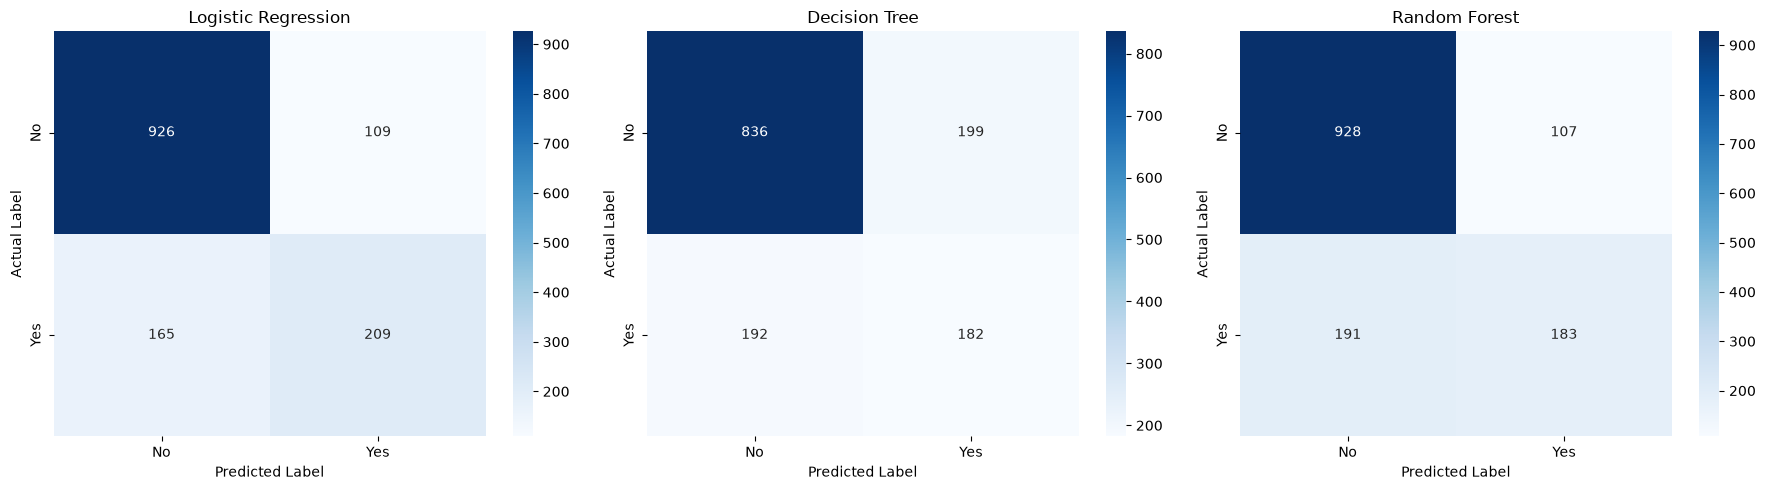

In [11]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrices
cm_logistic = confusion_matrix(y_test, y_pred_logistic, labels=["No", "Yes"])
cm_tree = confusion_matrix(y_test, y_pred_tree, labels=["No", "Yes"])
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"])

# Display all three confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    (cm_logistic, "Logistic Regression"),
    (cm_tree, "Decision Tree"),
    (cm_rf, "Random Forest")
]

for ax, (cm, title) in zip(axes, models):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

#### Observations

1. Logistic Regression correctly identified 209 customers who churned, outperforming the other two models.
2. Decision Tree incorrectly classified 199 customers as churners even though they stayed.
3. Random Forest correctly identified 928 customers who stayed, the highest among the three models.
4. Logistic Regression had the lowest number of false negatives (165), meaning it missed fewer actual churners.
5. All three models still have scope for improvement in identifying customers likely to churn.

#### Conclusion

Based on the confusion matrix results, Logistic Regression currently performs best at identifying actual churners among the three baseline models.

However, further optimization is required to reduce false negatives and improve churn detection.

### 5.5 ROC-AUC Evaluation

ROC-AUC is an important evaluation metric used to measure how effectively a classification model distinguishes between positive and negative classes.

In our telecom churn prediction project:

- Positive class: Churn (`Yes`)
- Negative class: No Churn (`No`)

The ROC curve illustrates the relationship between the True Positive Rate and False Positive Rate at different classification thresholds.

The AUC score measures the overall ability of the model to distinguish between customers who churn and customers who stay.

A higher AUC score generally indicates better class discrimination.

In [12]:
# Get churn probabilities from each model

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [13]:
logistic_model.predict_proba(X_test)[:, 1]

array([0.04605857, 0.68364788, 0.05872542, ..., 0.15427045, 0.00435676,
       0.00632071], shape=(1409,))

#### 5.5.1 Calculating ROC-AUC Scores

In this step, we will calculate the ROC-AUC score for Logistic Regression, Decision Tree and Random Forest.

These scores help compare how effectively each model distinguishes between customers who churn and customers who stay.

In [14]:
from sklearn.metrics import roc_auc_score

# Calculate ROC-AUC scores
auc_logistic = roc_auc_score(y_test, y_prob_logistic)
auc_tree = roc_auc_score(y_test, y_prob_tree)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Logistic Regression ROC-AUC:", auc_logistic)
print("Decision Tree ROC-AUC:", auc_tree)
print("Random Forest ROC-AUC:", auc_rf)

Logistic Regression ROC-AUC: 0.8420341522643313
Decision Tree ROC-AUC: 0.6469322379808313
Random Forest ROC-AUC: 0.820127102224289


#### Observations

1. Logistic Regression achieved the highest ROC-AUC score of 84.20%.
2. Random Forest achieved a ROC-AUC score of 82.01%, showing good class discrimination.
3. Decision Tree achieved the lowest ROC-AUC score of 64.69%.
4. Logistic Regression performs best among the three models in distinguishing churners from non-churners.

#### Conclusion

Based on ROC-AUC scores, Logistic Regression currently demonstrates the strongest ability to distinguish between customers who are likely to churn and customers who are likely to stay.

Further optimization will be explored to improve the overall prediction performance.

#### 5.5.2 ROC Curve Visualization

In this step, we will plot the ROC curves of Logistic Regression, Decision Tree and Random Forest on the same graph.

The curves will help us visually compare the classification performance of all three models.

A model with a curve closer to the top-left corner generally has better class discrimination.

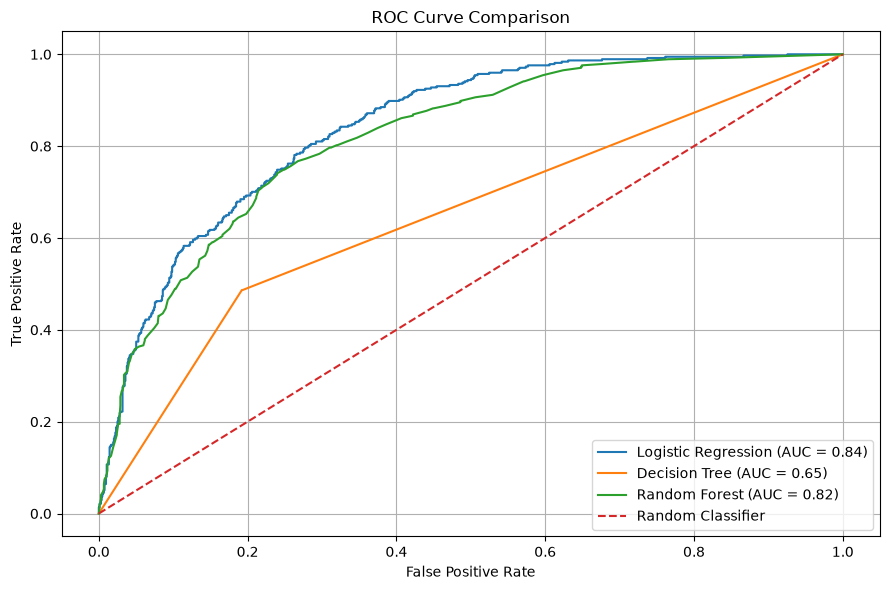

In [15]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test, y_prob_logistic, pos_label="Yes"
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test, y_prob_tree, pos_label="Yes"
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test, y_prob_rf, pos_label="Yes"
)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_logistic, tpr_logistic,
    label=f"Logistic Regression (AUC = {auc_logistic:.2f})"
)

plt.plot(
    fpr_tree, tpr_tree,
    label=f"Decision Tree (AUC = {auc_tree:.2f})"
)

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.2f})"
)

# Random classification reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

#### Observations

1. Logistic Regression achieved the highest AUC score of 0.84, indicating strong classification performance.
2. Random Forest achieved an AUC score of 0.82 and also demonstrated good class discrimination.
3. Decision Tree achieved the lowest AUC score of 0.65.
4. The Logistic Regression ROC curve is closer to the top-left corner compared with the other models.
5. All three models perform better than the random classifier baseline.

#### Conclusion

Based on the ROC curve and AUC scores, Logistic Regression currently demonstrates the best ability to distinguish between customers who churn and customers who stay.

Further model optimization will be performed to improve the identification of potential churners.

## 6. Feature Importance Analysis

In this section, we will identify the features that contribute most to customer churn predictions.

Feature importance analysis helps us understand which customer characteristics are influential in the predictions made by machine learning models.

We will examine:

1. Random Forest feature importance
2. Decision Tree feature importance
3. Logistic Regression coefficients

The findings can help identify important customer characteristics and provide useful insights for telecom customer retention strategies.

In [17]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
c:\Users\jeevan\Desktop\Telecom-Customer-Churn-Prediction\notebooks


In [18]:
import os

file_path = "../models/preprocessing_objects.joblib"

print("File exists:", os.path.exists(file_path))
print("Models folder exists:", os.path.exists("../models"))

File exists: False
Models folder exists: True


In [19]:
import os

print(os.listdir("../models"))

['decision_tree.pkl', 'logistic_regression.pkl', 'random_forest.pkl']


In [20]:
import os

print("Preprocessing file exists:",
      os.path.exists("../models/preprocessing_objects.joblib"))

Preprocessing file exists: True


In [21]:
import joblib

# Load preprocessing objects
preprocessing_objects = joblib.load(
    "../models/preprocessing_objects.joblib"
)

# Retrieve fitted encoder and feature lists
encoder = preprocessing_objects["encoder"]

numerical_features = preprocessing_objects["numerical_features"]

categorical_features = preprocessing_objects["categorical_features"]

# Get encoded categorical feature names
encoded_features = encoder.get_feature_names_out(
    categorical_features
)

# Combine all feature names
feature_names = list(numerical_features) + list(encoded_features)

print("Total number of features:", len(feature_names))
print("\nFeature names:")
print(feature_names)

Total number of features: 46

Feature names:
['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Female', 'gender_Male', 'Partner_No', 'Partner_Yes', 'Dependents_No', 'Dependents_Yes', 'PhoneService_No', 'PhoneService_Yes', 'MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_No', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automat

### 6.1 Random Forest Feature Importance

Random Forest provides a feature importance score for each input variable.

These scores help us understand which features contributed most to the model's decision-making process.

We will extract the importance scores, associate them with their corresponding feature names and identify the most influential features.

In [22]:
# Extract feature importance scores
rf_importance = random_forest_model.feature_importances_

# Create a DataFrame
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

# Sort features by importance
rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 important features
rf_importance_df.head(10)

,Feature,Importance
2,TotalCharges,0.156434
0,tenure,0.139784
1,MonthlyCharges,0.133104
35,Contract_Month-to-month,0.056073
42,PaymentMethod_Electronic check,0.032483
17,OnlineSecurity_No,0.032446
26,TechSupport_No,0.030475
15,InternetService_Fiber optic,0.024558
3,gender_Female,0.018344
4,gender_Male,0.018318


#### 6.1.1 Visualizing Random Forest Feature Importance

In this step, we will visualize the top 10 important features identified by the Random Forest model.

The horizontal bar chart will help us easily compare the relative importance of different customer characteristics.

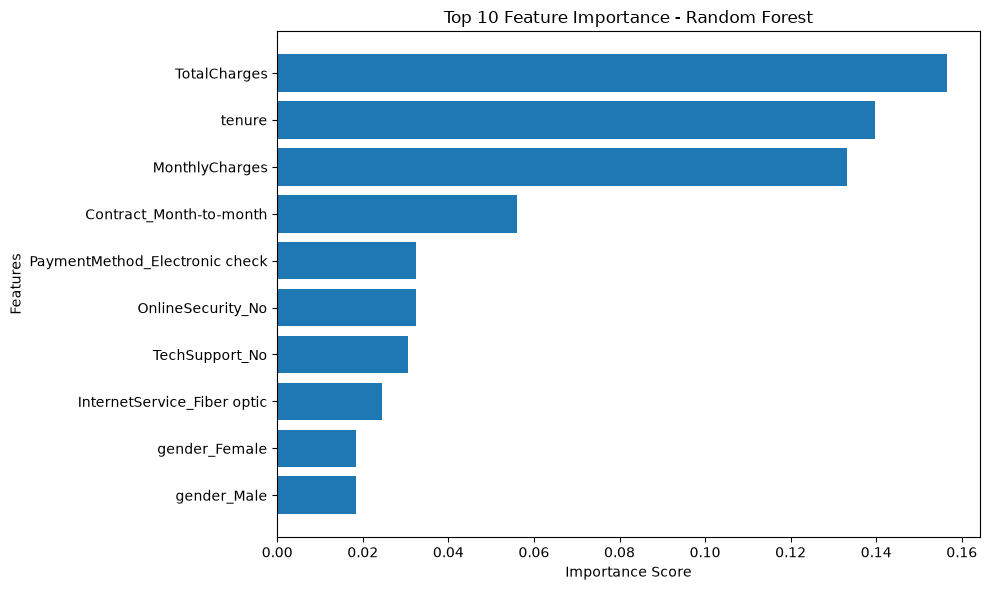

In [23]:
# Select top 10 features
top_10_features = rf_importance_df.head(10)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### Observations

1. TotalCharges is the most important feature, with an importance score of approximately 0.156.
2. Tenure is the second most important feature, with a score of approximately 0.140.
3. MonthlyCharges ranks third, with a score of approximately 0.133.
4. Contract_Month-to-month also contributes considerably to churn prediction.
5. Payment method, online security, technical support and internet service contribute to the model's predictions.

#### Conclusion

The Random Forest model identifies TotalCharges, tenure and MonthlyCharges as its three most important features.

These findings highlight the importance of customer billing information, service duration and contract-related characteristics in predicting telecom customer churn.

Feature importance indicates predictive contribution and does not establish causation.

### 6.2 Decision Tree Feature Importance

In this step, we will calculate feature importance scores using the trained Decision Tree model.

These scores help identify which customer characteristics contribute most to the model's predictions.

We will rank the features based on their importance and examine the top 10 features.

In [25]:
# Extract feature importance scores
dt_importance = decision_tree_model.feature_importances_

# Create a DataFrame
dt_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": dt_importance
})

# Sort features by importance
dt_importance_df = dt_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 important features
dt_importance_df.head(10)

,Feature,Importance
2,TotalCharges,0.191986
1,MonthlyCharges,0.181468
35,Contract_Month-to-month,0.166082
0,tenure,0.125511
15,InternetService_Fiber optic,0.052756
42,PaymentMethod_Electronic check,0.020029
4,gender_Male,0.018548
26,TechSupport_No,0.017469
20,OnlineBackup_No,0.012709
43,PaymentMethod_Mailed check,0.011465


#### 6.2.1 Visualizing Decision Tree Feature Importance

In this step, we will create a horizontal bar chart to visualize the top 10 important features identified by the Decision Tree model.

This visualization will help us understand the relative contribution of different customer characteristics to the model's predictions.

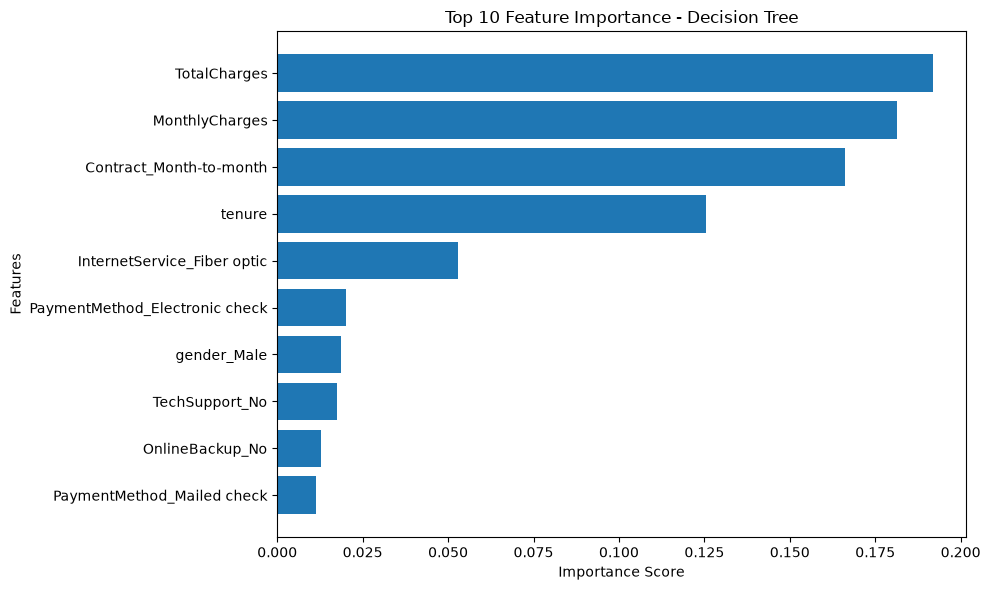

In [26]:
# Select top 10 features
top_10_dt = dt_importance_df.head(10)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_dt["Feature"],
    top_10_dt["Importance"]
)

plt.title("Top 10 Feature Importance - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### Observations

1. TotalCharges is the most important feature, with an importance score of approximately 0.192.
2. MonthlyCharges ranks second, with an importance score of approximately 0.181.
3. Contract_Month-to-month ranks third, contributing approximately 0.166.
4. Tenure is the fourth most important feature, with an importance score of approximately 0.126.
5. Both Decision Tree and Random Forest identify TotalCharges, MonthlyCharges, Contract_Month-to-month and tenure among their top four features.

#### Conclusion

The Decision Tree model identifies billing information, contract type and customer tenure as important features for predicting churn.

Although both tree-based models identify similar important features, their importance scores differ because their learning structures and prediction processes are different.

### 6.3 Logistic Regression Coefficient Analysis

Logistic Regression uses coefficients to understand the relationship between input features and the predicted outcome.

Positive coefficients indicate an increase in the predicted odds of customer churn, while negative coefficients indicate a decrease.

In this step, we will extract the coefficients from the trained Logistic Regression model and identify the features with the strongest positive and negative coefficients.

In [27]:
# Extract coefficients
logistic_coefficients = logistic_model.coef_[0]

# Create a DataFrame
logistic_coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_coefficients
})

# Sort by absolute coefficient magnitude
logistic_coef_df["Absolute_Coefficient"] = (
    logistic_coef_df["Coefficient"].abs()
)

logistic_coef_df = logistic_coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

# Display top 10 features
logistic_coef_df.head(10)

,Feature,Coefficient,Absolute_Coefficient
0,tenure,-1.255202,1.255202
37,Contract_Two year,-0.759402,0.759402
15,InternetService_Fiber optic,0.648027,0.648027
14,InternetService_DSL,-0.643642,0.643642
1,MonthlyCharges,-0.601168,0.601168
35,Contract_Month-to-month,0.585998,0.585998
2,TotalCharges,0.532592,0.532592
38,PaperlessBilling_No,-0.330735,0.330735
21,OnlineBackup_No internet service,-0.292955,0.292955
16,InternetService_No,-0.292955,0.292955


#### Observations

1. Tenure has the strongest coefficient magnitude (-1.2552), indicating that higher tenure is associated with lower churn odds.
2. Contract_Two year has a negative coefficient, suggesting lower churn odds for customers with two-year contracts.
3. InternetService_Fiber optic has a positive coefficient, indicating higher churn odds.
4. Contract_Month-to-month has a positive coefficient, suggesting higher churn odds.
5. MonthlyCharges has a negative coefficient in the multivariable model, despite showing a positive association with churn in our earlier EDA.

#### Conclusion

The Logistic Regression coefficients highlight the relationships between customer characteristics and predicted churn odds.

Tenure, contract type and internet service are among the features with the largest coefficient magnitudes.

These relationships are conditional on the other features included in the model and should not be interpreted as causal effects.

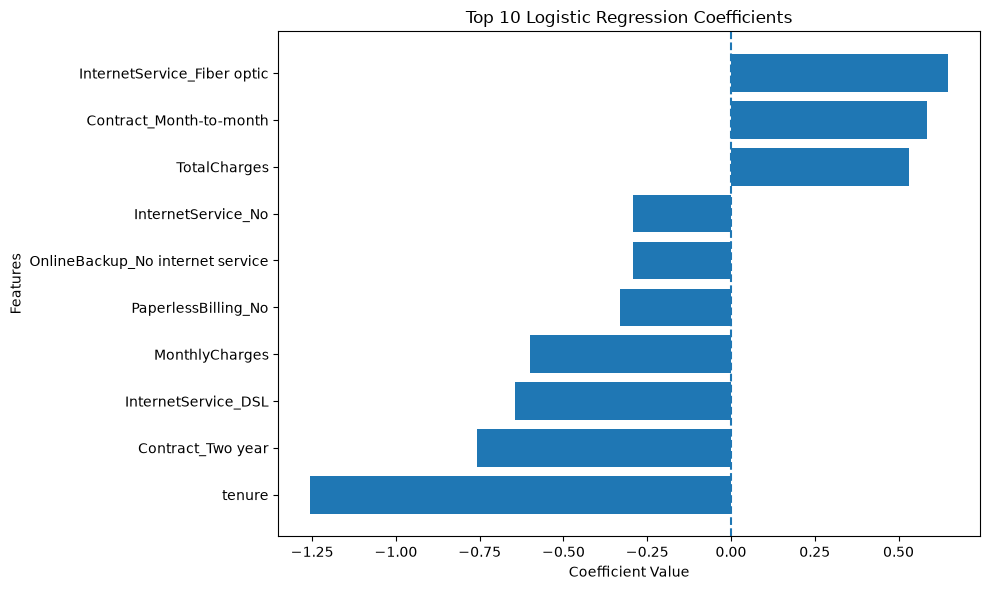

In [28]:
# Select top 10 features
top_10_logistic = logistic_coef_df.head(10).sort_values(
    by="Coefficient"
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_logistic["Feature"],
    top_10_logistic["Coefficient"]
)

# Add reference line at zero
plt.axvline(x=0, linestyle="--")

plt.title("Top 10 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

#### Observations

1. Tenure has the strongest negative coefficient (-1.255), indicating an association with lower churn odds.
2. Contract_Two year has a negative coefficient (-0.759), suggesting lower churn odds.
3. InternetService_Fiber optic has the strongest positive coefficient (+0.648), indicating higher churn odds.
4. Contract_Month-to-month has a positive coefficient (+0.586).
5. TotalCharges has a positive coefficient (+0.533).

#### Conclusion

The Logistic Regression coefficient analysis highlights tenure, contract type and internet service as important features associated with customer churn.

Positive coefficients indicate higher predicted churn odds, while negative coefficients indicate lower predicted churn odds, holding other features constant.

These findings provide additional insight into the relationships learned by the Logistic Regression model.

### 6.4 Combined Feature Importance Comparison

In this step, we will compare the important features identified by Logistic Regression, Decision Tree and Random Forest.

Since these models use different methods to calculate feature importance, we will compare their feature rankings rather than directly comparing their raw scores.

This analysis helps identify customer characteristics that consistently contribute to churn predictions across different machine learning models.

In [30]:
# Prepare Random Forest importance
rf_compare = rf_importance_df[
    ["Feature", "Importance"]
].copy()

rf_compare.rename(
    columns={"Importance": "Random_Forest"},
    inplace=True
)

# Prepare Decision Tree importance
dt_compare = dt_importance_df[
    ["Feature", "Importance"]
].copy()

dt_compare.rename(
    columns={"Importance": "Decision_Tree"},
    inplace=True
)

# Prepare Logistic Regression coefficient magnitude
lr_compare = logistic_coef_df[
    ["Feature", "Absolute_Coefficient"]
].copy()

lr_compare.rename(
    columns={"Absolute_Coefficient": "Logistic_Regression"},
    inplace=True
)

# Combine all three results
combined_importance = rf_compare.merge(
    dt_compare, on="Feature"
).merge(
    lr_compare, on="Feature"
)

# Calculate feature rankings
combined_importance["RF_Rank"] = (
    combined_importance["Random_Forest"]
    .rank(ascending=False)
)

combined_importance["DT_Rank"] = (
    combined_importance["Decision_Tree"]
    .rank(ascending=False)
)

combined_importance["LR_Rank"] = (
    combined_importance["Logistic_Regression"]
    .rank(ascending=False)
)

# Calculate average ranking
combined_importance["Average_Rank"] = (
    combined_importance[
        ["RF_Rank", "DT_Rank", "LR_Rank"]
    ].mean(axis=1)
)

# Display top 15 consistently ranked features
combined_importance = combined_importance.sort_values(
    by="Average_Rank"
)

combined_importance.head(15)

C:\Users\jeevan\AppData\Local\Temp\ipykernel_23748\13526875.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rf_compare.rename(
C:\Users\jeevan\AppData\Local\Temp\ipykernel_23748\13526875.py:16: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dt_compare.rename(
C:\Users\jeevan\AppData\Local\Temp\ipykernel_23748\13526875.py:26: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  lr_compare.rename(


,Feature,Random_Forest,Decision_Tree,Logistic_Regression,RF_Rank,DT_Rank,LR_Rank,Average_Rank
1,tenure,0.139784,0.125511,1.255202,2.0,4.0,1.0,2.333333
0,TotalCharges,0.156434,0.191986,0.532592,1.0,1.0,7.0,3.000000
2,MonthlyCharges,0.133104,0.181468,0.601168,3.0,2.0,5.0,3.333333
3,Contract_Month-to-month,0.056073,0.166082,0.585998,4.0,3.0,6.0,4.333333
7,InternetService_Fiber optic,0.024558,0.052756,0.648027,8.0,5.0,3.0,5.333333
4,PaymentMethod_Electronic check,0.032483,0.020029,0.205585,5.0,6.0,24.0,11.666667
12,PaperlessBilling_No,0.015691,0.010199,0.330735,13.0,14.0,8.0,11.666667
6,TechSupport_No,0.030475,0.017469,0.141320,7.0,8.0,31.0,15.333333
8,gender_Female,0.018344,0.010769,0.155230,9.0,11.0,29.0,16.333333
5,OnlineSecurity_No,0.032446,0.008972,0.165550,6.0,18.0,26.0,16.666667


#### Observations

1. Tenure achieved the highest overall ranking, with an average rank of 2.33.
2. TotalCharges ranked second, with an average rank of 3.00.
3. MonthlyCharges ranked third, with an average rank of 3.33.
4. Contract_Month-to-month ranked fourth, with an average rank of 4.33.
5. InternetService_Fiber optic ranked fifth, with an average rank of 5.33.
6. All three models identified tenure, billing information and contract-related features as useful predictors of customer churn.

#### Conclusion

The combined comparison suggests that tenure, TotalCharges, MonthlyCharges and contract type are consistently important predictive features across the three models.

These findings help identify customer characteristics that may be useful when developing customer retention strategies.

The average ranking is an exploratory comparison because the three models use different feature importance measures.

## 7. Final Model Performance Comparison

In this section, we will compare the performance of Logistic Regression, Decision Tree and Random Forest using all the evaluation metrics calculated previously.

The comparison includes:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

This consolidated comparison will help us understand the strengths and weaknesses of each model and identify the strongest baseline model for telecom customer churn prediction.

In [31]:
# Create final model comparison DataFrame

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf
    ],
    "Precision": [
        precision_logistic,
        precision_tree,
        precision_rf
    ],
    "Recall": [
        recall_logistic,
        recall_tree,
        recall_rf
    ],
    "F1-score": [
        f1_logistic,
        f1_tree,
        f1_rf
    ],
    "ROC-AUC": [
        auc_logistic,
        auc_tree,
        auc_rf
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.842034
1,Decision Tree,0.722498,0.477690,0.486631,0.482119,0.646932
2,Random Forest,0.788502,0.631034,0.489305,0.551205,0.820127


#### Observations

1. Logistic Regression achieved the highest accuracy of 80.55%.
2. Logistic Regression also achieved the highest precision (65.72%), recall (55.88%), F1-score (60.40%) and ROC-AUC (84.20%).
3. Decision Tree showed the weakest overall performance among the three models.
4. Random Forest achieved 78.85% accuracy and 82.01% ROC-AUC, making it the second-best baseline model.
5. Logistic Regression identified 209 actual churners out of 374, but still missed 165 customers who churned.

#### Final Baseline Model Selection

Based on the evaluation results, Logistic Regression is selected as the strongest baseline model.

However, its recall indicates that there is still room for improvement in identifying customers likely to churn.

Further model optimization and tuning will be performed to improve churn prediction performance.